# Random Number Generators

Moreno Marzolla

Last modified: 2026-11-23

---

Given integer parameters $a, c, m$, a Linear Congruential Generator (LCG) is a recurrence equation:

$$
x_n = (ax_{n-1} + c) \mod m
$$

Starting from an initial _seed_ $x_0$, a LCG generates a sequence of integers in $\{0, \ldots, m-1\}$.

We can realize a generic LCG as a Python generator.

In [1]:
def LCG(a, c, m, x0):
    x = x0
    while True:
        yield x
        x = (a*x + c) % m

Foe example, let us consider the recurrence $x_n = (5x_{n-1} +1) \mod 16$. It can be shown that this generator has cycle length 16 (the maximum possible), as we can empirically observe by picking a seed, say $x_0 = 0$.

In [2]:
import itertools as it

r = LCG(5, 1, 16, 0)

print(list(it.islice(r, 32)))

[0, 1, 6, 15, 12, 13, 2, 11, 8, 9, 14, 7, 4, 5, 10, 3, 0, 1, 6, 15, 12, 13, 2, 11, 8, 9, 14, 7, 4, 5, 10, 3]


LCGs are very simple and fast. However, they have a small state space and often are unable to achieve maximum cycle length. 

A simple way to check the "goodness" of a LCG is through a [spectral test](https://en.wikipedia.org/wiki/Spectral_test). Given a sequence of random numbes $x_0, x_1, \ldots$, a $d$-dimensional spectral test consists of plotting the points $(x_n, x_{n+1}, \ldots, x_{n+d-1})$ in $d$-dimensional space. LCGs have the property that for some dimension $d \geq 2$  the points will eventually lie on a set of parallel hyperplanes; the farther away the hyperplanes are, the worse the generator is. 

In two dimensions, we plot the points of coordinates $(x_0, x_1), (x_1, x_2), (x_2, x_3), \ldots$, and so on, and look whether the points appears to be uniformly scattered over the plane or lie over parallel lines.

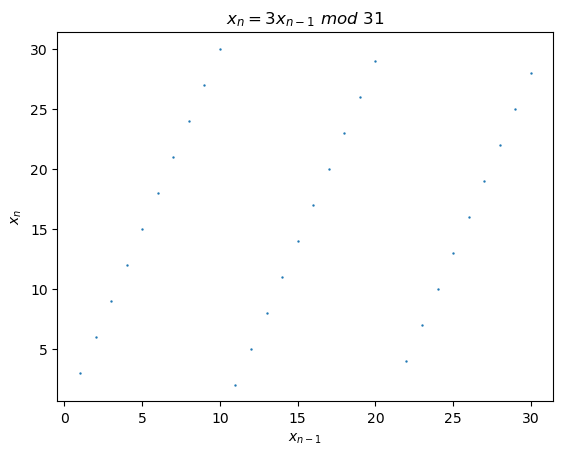

In [3]:
import numpy as np
from matplotlib import pyplot as plt
#plt.rcParams['figure.dpi'] = 200

bad = np.fromiter(LCG(3, 0, 31, 1), dtype=float, count=30)
plt.scatter(bad[:-1], bad[1:], s=0.5)
plt.xlabel("$x_{n-1}$")
plt.ylabel("$x_n$")
plt.title(r"$x_n = 3x_{n-1}\ mod\ 31$")
plt.show()

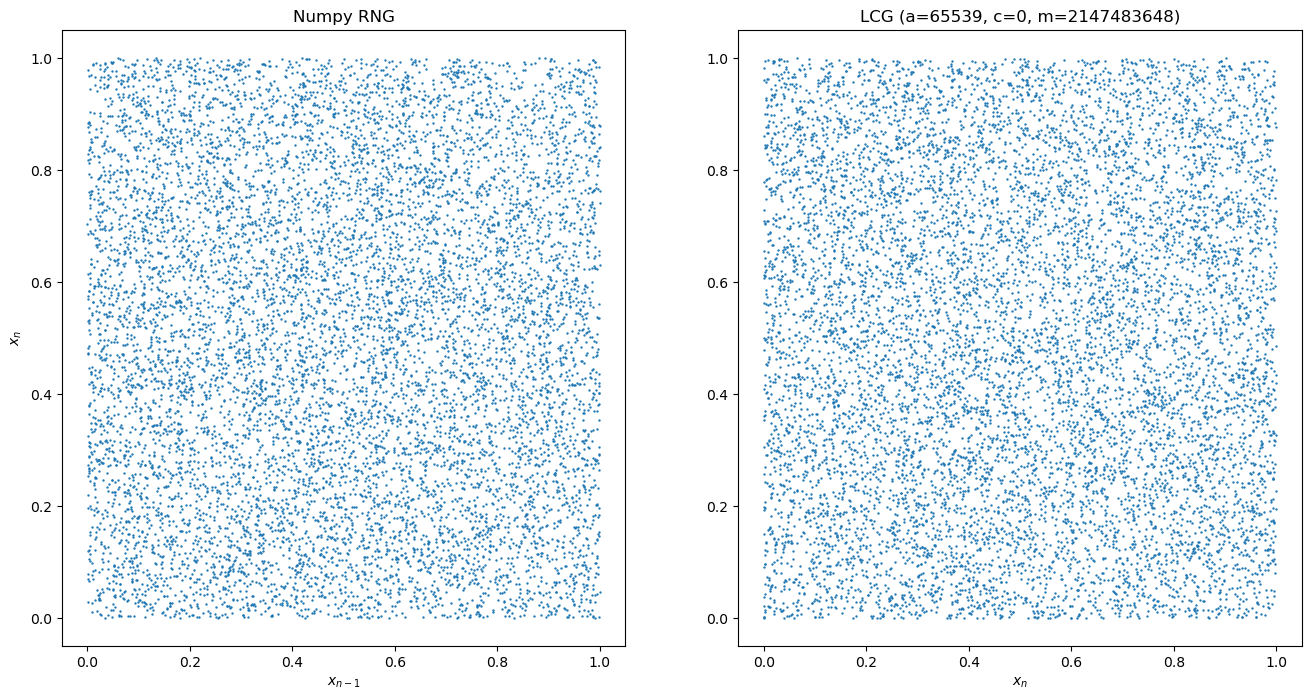

In [4]:
N = 10000
# generate N random numbers in (0,1) using Python's random()
rpython = np.random.default_rng(123).random(N)
# a, c, m, x0 = 3, 0, 31, 1
# generate N random numbers using LCG(65539, 0, 2**31); normalize to (0,1)
a, c, m, x0 = 65539, 0, 2**31, 17
rlcg = np.fromiter(LCG(a, c, m, x0), dtype=float, count=N) / (2.0**31-1)

plt.subplots(1, 2, figsize=(16,8))

plt.subplot(1,2,1)
plt.scatter(rpython[:-1], rpython[1:], s=0.5)
plt.title("Numpy RNG")
plt.xlabel("$x_{n-1}$")
plt.ylabel("$x_n$")

plt.subplot(1,2,2)
plt.scatter(rlcg[:-1], rlcg[1:], s=0.5)
plt.title(f"LCG (a={a}, c={c}, m={m})")
plt.xlabel("$x_n$")

plt.show()

$\text{LCG}(65539, 0, 2^{31})$ appears to be "as random as" Python's default RNG in two dimensions. Let us repeat the spectral test in three dimensions.

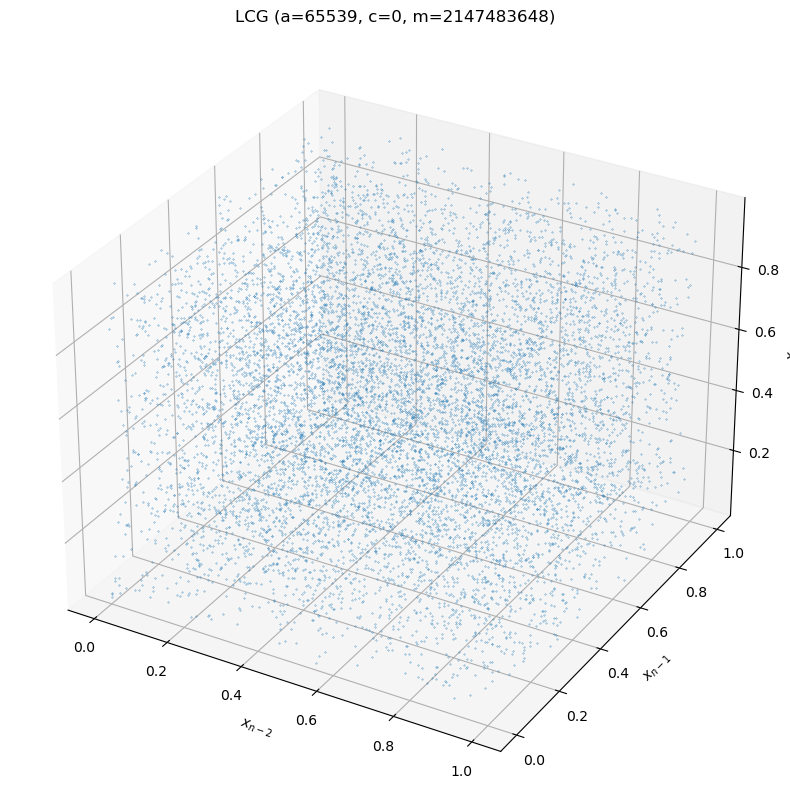

In [5]:
ax = plt.figure(figsize=(10,10)).add_subplot(projection="3d")
plt.plot(rlcg[:-2], rlcg[1:-1], rlcg[2:], '.', markersize=0.5)
#ax.view_init(azim=65)
plt.title(f"LCG (a={a}, c={c}, m={m})")
ax.set_xlabel("$x_{n-2}$")
ax.set_ylabel("$x_{n-1}$")
ax.set_zlabel("$x_n$")
plt.show()

Again, the points appear to be randomly distributed in three-dimensional space. However, try to change che viewpoint by uncommenting the instruction `ax.view_init(azim=65)`...